# SNR: Visualizando el efecto del ruido en imágenes

Este notebook te permite **subir una imagen**, añadir ruido gaussiano para alcanzar **SNR objetivo (dB)**, y visualizar cómo evoluciona la calidad. Incluye:



In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


import scipy.stats as stats
from skimage.metrics import structural_similarity as ssim

from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Leer la imagen en escala de grises
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

Saving michael_2.jpg to michael_2 (1).jpg


In [12]:
img.shape


(239, 211)

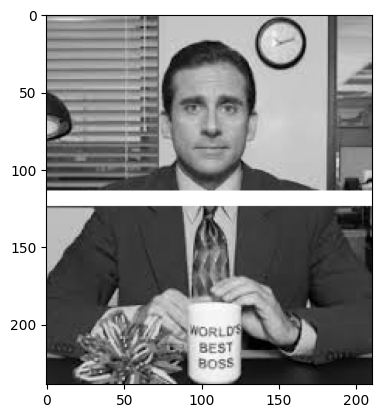

In [13]:
mitad = img.shape[0] / 2
y0,y1 = int(mitad - 5), int(mitad + 5)
region = img[int(y0):int(y1),:]

# pintar region en imagen
img_copy = img.copy()
img_copy[y0:y1,:] = 255
plt.imshow(img_copy, cmap='gray')

In [14]:
# Promedio intensidad en region
signal = np.mean(region, axis=0)
print(len(signal))
print(signal)

211
[117.3 117.3 117.3 117.4 117.5 117.7 117.7 117.8 119.1 119.1 119.4 119.6
 119.8 120.1 120.3 120.3 120.8 121.  121.3 121.7 122.3 122.7 123.1 123.3
 126.2 122.1 125.6 124.5 125.9 126.4  99.6  66.2  55.7  53.9  52.9  54.7
  57.9  60.   59.2  57.   60.4  58.5  56.2  54.2  54.   55.8  57.8  59.6
  56.9  57.   57.1  57.4  57.6  58.   58.   58.2  57.4  57.5  58.2  58.8
  59.3  59.6  60.2  60.3  56.5  57.7  58.8  58.8  58.   57.6  58.1  58.8
  62.8  62.3  61.5  60.8  60.   59.1  58.4  58.1  58.1  53.6  56.4  57.9
  61.3  57.   69.  136.  181.  181.2 182.4 184.1 186.9 190.1 193.  194.8
 197.1 198.5 199.6 194.3 169.7 129.6 101.7  88.3  87.9  96.3 109.3 115.
 118.3 113.6 113.8 127.6 155.  183.  195.4 196.8 194.3 192.2 185.4 182.3
 172.2 174.6 172.9 170.4 103.9  52.1  59.8  57.7  59.7  59.7  59.8  59.6
  59.9  60.1  60.   60.1  60.7  60.5  60.   59.4  58.7  58.1  57.7  57.3
  57.6  57.6  57.7  57.7  57.6  57.7  57.6  57.7  58.5  58.7  58.8  58.9
  59.1  59.3  59.3  59.5  59.5  59.3  59.3  59.1

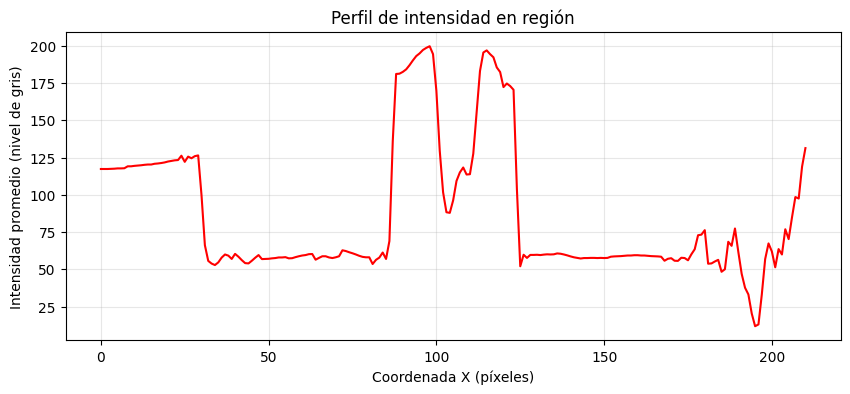

In [15]:


# Dibujamos el perfil de intensidad sin modificar la imagen original
plt.figure(figsize=(10, 4))
plt.title("Perfil de intensidad en región")
plt.plot(signal, color='red')
plt.xlabel("Coordenada X (píxeles)")
plt.ylabel("Intensidad promedio (nivel de gris)")
plt.grid(True, alpha=0.3)
plt.show()

In [16]:
def add_noise_for_snr(image, snr_db, region_mask=None):
    # Convertir la imagen a float para evitar problemas de tipo de dato (ej. uint8)
    image_float = image.astype(np.float32)

    # Si no se proporciona mascara, usar toda la imagen
    svals = image_float[region_mask] if region_mask is not None else image_float

    # Potencia media de la señal
    Ps = np.mean(np.square(svals))

    # Potencia del ruido despejada de SNR_dB = 10 * log10(Ps / Pn)
    PS_PN = 10.0 ** (snr_db / 10.0)
    Pn = Ps / PS_PN

    # Desviación estándar del ruido gaussiano (ruido con media 0)
    sigma = np.sqrt(Pn)

    # Generar el ruido con la misma forma que la imagen original
    noise = np.random.normal(loc=0.0, scale=sigma, size=image.shape).astype(np.float32)

    # Sumar el ruido
    noisy = image_float + noise

    # Opcional: Descomentar si tu imagen es uint8 [0, 255] y deseas devolver el mismo tipo
    # noisy = np.clip(noisy, 0, 255).astype(image.dtype)

    return noisy

In [17]:
def calculate_metrics(img_original, img_noisy):
    # Error Cuadrático Medio (MSE)
    mse = np.mean((img_original.astype(np.float64) - img_noisy.astype(np.float64)) ** 2)

    # Peak Signal-to-Noise Ratio (PSNR)
    if mse == 0:
        psnr = float('inf')
    else:
        MAX_I = 255.0
        psnr = 10 * np.log10((MAX_I ** 2) / mse)

    # Entropía de Shannon del histograma
    counts, _ = np.histogram(np.clip(img_noisy, 0, 255), bins=256, range=(0, 256))
    prob_dist = counts / counts.sum()
    prob_dist = prob_dist[prob_dist > 0]  # Filtrar ceros para el logaritmo
    entropy = -np.sum(prob_dist * np.log2(prob_dist))

    return mse, psnr, entropy

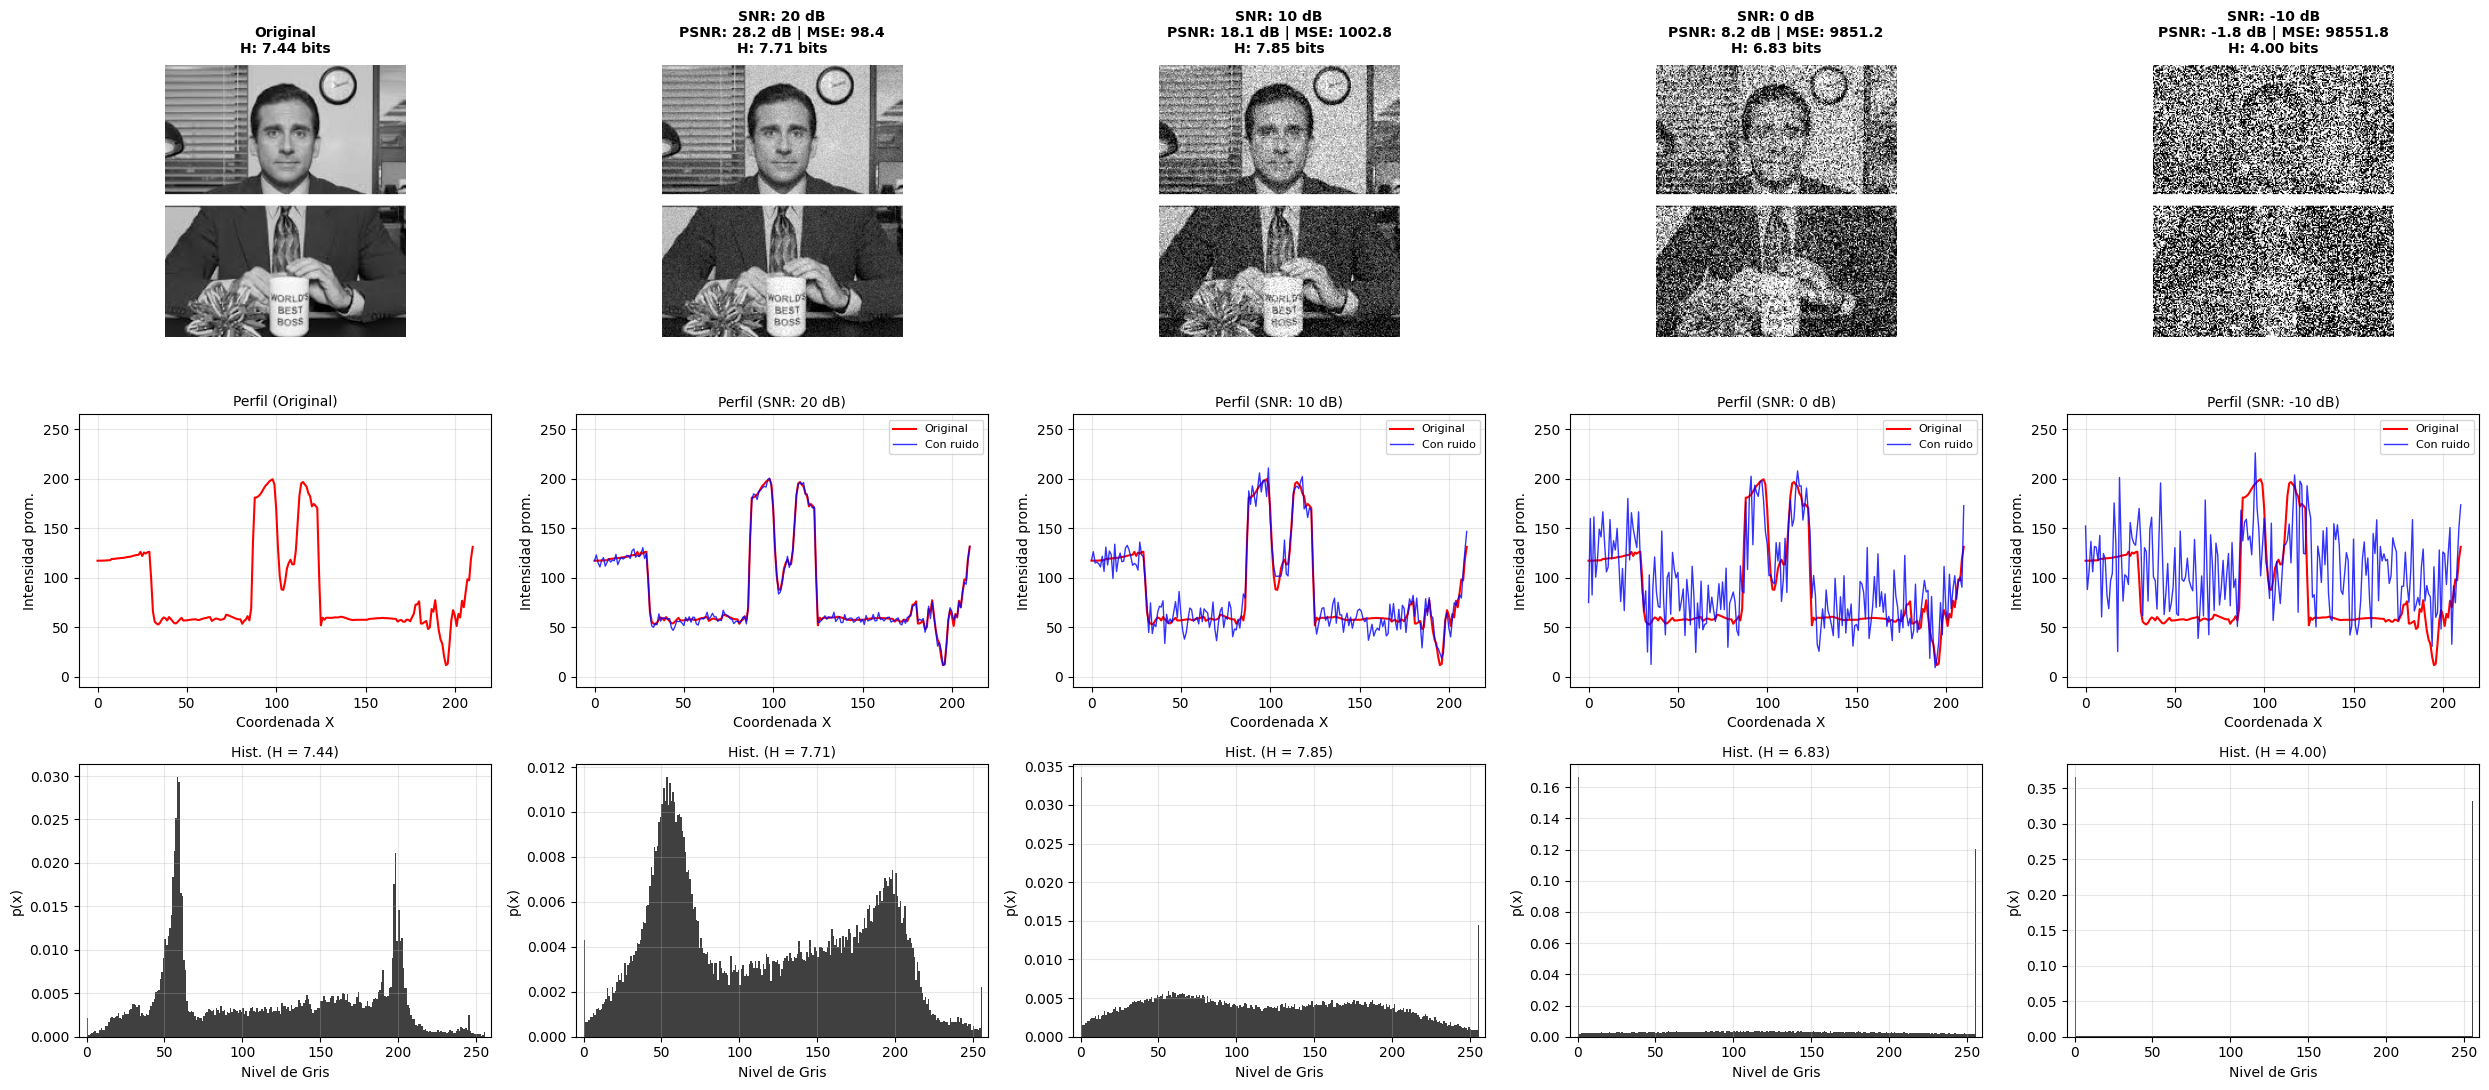

In [18]:


# 1. Definición correcta de la máscara según las 2 primeras dimensiones (alto, ancho)
mask = np.zeros(img.shape[:2], dtype=bool)
mask[y0:y1, :] = True

# 2. Perfil de intensidad original previo al bucle
signal = np.mean(img[y0:y1, :], axis=0)

# Generar versiones ruidosas
snr_list = [20, 10, 0, -10]
noisy_imgs = [add_noise_for_snr(img, snr_db, region_mask=mask) for snr_db in snr_list]

# Preparar títulos e imágenes (Total: 5 elementos)
titles = ["Original"] + [f"SNR: {snr} dB" for snr in snr_list]
images = [img] + noisy_imgs

metrics_summary = []

# 3. CORRECCIÓN PRINCIPAL: 3 filas x 5 columnas (para albergar los 5 escenarios)
fig, axes = plt.subplots(3, 5, figsize=(25, 11))

for i, (im, title) in enumerate(zip(images, titles)):
    # A. Calcular métricas
    mse, psnr, H = calculate_metrics(img, im)

    metrics_summary.append({
        "Escenario": title,
        "MSE": f"{mse:.2f}",
        "PSNR (dB)": f"{psnr:.2f}" if psnr != float('inf') else "∞",
        "Entropía H (bits)": f"{H:.4f}"
    })

    # Preparar imagen recortada al rango [0, 255]
    im_clipped = np.clip(im, 0, 255).astype(np.uint8)
    im_disp = im_clipped.copy()
    im_disp[y0:y1, :] = 255  # Marca la franja analizada

    # -------------------------------------------------------------
    # FILA 1: Imágenes
    # -------------------------------------------------------------
    ax_img = axes[0, i]
    ax_img.imshow(im_disp, cmap='gray', vmin=0, vmax=255)

    if i == 0:
        header_title = f"{title}\nH: {H:.2f} bits"
    else:
        header_title = f"{title}\nPSNR: {psnr:.1f} dB | MSE: {mse:.1f}\nH: {H:.2f} bits"

    ax_img.set_title(header_title, fontsize=10, fontweight='bold', pad=8)
    ax_img.axis('off')

    # -------------------------------------------------------------
    # FILA 2: Perfiles de Intensidad
    # -------------------------------------------------------------
    roi_noisy = im_clipped[y0:y1, :]
    signal_noisy = np.mean(roi_noisy, axis=0)

    ax_prof = axes[1, i]
    ax_prof.plot(signal, color='red', linewidth=1.5, label='Original')
    if i > 0:
        ax_prof.plot(signal_noisy, color='blue', alpha=0.8, linewidth=1, label='Con ruido')
        ax_prof.legend(loc='upper right', fontsize=8)

    ax_prof.set_title(f"Perfil ({title})", fontsize=10)
    ax_prof.set_xlabel("Coordenada X")
    ax_prof.set_ylabel("Intensidad prom.")
    ax_prof.set_ylim(-10, 265)
    ax_prof.grid(True, alpha=0.3)

    # -------------------------------------------------------------
    # FILA 3: Histogramas de Intensidad
    # -------------------------------------------------------------
    ax_hist = axes[2, i]
    ax_hist.hist(im_clipped.ravel(), bins=256, range=(0, 256), color='black', alpha=0.75, density=True)
    ax_hist.set_title(f"Hist. (H = {H:.2f})", fontsize=10)
    ax_hist.set_xlabel("Nivel de Gris")
    ax_hist.set_ylabel("p(x)")
    ax_hist.set_xlim(-5, 260)
    ax_hist.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

El histograma se destruye hacia una distribución plana, provocando un incremento en la entropía de la imagen por pérdida de información estructurada.

Cuanto más puntiaguda y concentrada es una distribución de probabilidad (pocos valores concentran todo el peso), menor es su entropía.

Cuanto más plana y uniforme es una distribución (todos los valores son igualmente equiprobables), mayor es su entropía (alcanza su máximo teórico).

In [ ]:
print("\n--- RESUMEN DE MÉTRICAS ANALÍTICAS ---")
df_metrics = pd.DataFrame(metrics_summary)
display(df_metrics)


--- RESUMEN DE MÉTRICAS ANALÍTICAS ---


,Escenario,MSE,PSNR (dB),Entropía H (bits)
0,Original,0.00,∞,2.1048
1,SNR: 20 dB,0.39,52.22,2.9460
2,SNR: 0 dB,38.99,32.22,4.1532
3,SNR: -10 dB,390.67,22.21,4.7029
